# Wet and dry days: a non-Gaussian likelihood with the path integrated out or sampled

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/ssm_nongauss.ipynb)

In Examples [1](ssm_one_site.ipynb), [2](ssm_hierarchical_sites.ipynb) and [3](ssm_shared_plus_site.ipynb) the observations were Gaussian, so the Kalman filter integrated the latent path out exactly and NUTS only saw the hyperparameters. In [Example 3b](ssm_spatial_hierarchical.ipynb) the observations were counts, and NUTS had to sample every latent value. Here we take one station's record of wet and dry days, a Bernoulli observation of a latent log odds, and fit it both ways. Route A integrates the path out approximately with a Laplace approximation, so NUTS again samples only the hyperparameters. Route B samples the path through whitened innovations, as Example 3b did, so its posterior is exact up to the Monte Carlo error of the chains. Since we simulate the record, we know the truth, and Route B gives us the reference to check Route A against: its hyperparameters, its latent wet-day probability through the gaps and the forecast, and what it costs.

**pyrox-ssm capability shown:** `markov_laplace_factor`, which fits the latent path with a site-based strategy (`LaplaceMarkovInference` here, `ExpectationPropagationMarkov` for comparison) and adds its approximate log evidence as a NumPyro factor, with `reject_unconverged=True` so NUTS rejects any $\boldsymbol{\theta}$ whose fit did not converge; `MarkovGPPrior.condition_nongauss(...).predict(...)`, the conditioned non-Gaussian posterior at arbitrary days; and `markov_gp_innovations_sample` for Route B. The strategies iterate to a fixed point with `optimistix.fixed_point`, and their gradient comes from the implicit function theorem at that fixed point, so the factor jits and differentiates inside NUTS. **Cost:** every Route A log-density evaluation is a few Kalman filter and smoother passes, $\mathcal{O}(I N D_x^3)$ for $I$ fixed-point iterations, plus the implicit gradient; every Route B evaluation is one scan, $\mathcal{O}(T D_x^3)$, but NUTS has to move $T D_x$ more values. We measure both, per gradient, per draw and per effective sample, in section 8.

**What you'll learn:**

1. How to write a Bernoulli model on a Markov GP as a plain NumPyro function in two ways: with the path collapsed by `markov_laplace_factor`, and with the path sampled by `markov_gp_innovations_sample`.
2. How the hyperparameter posteriors of the two routes compare with each other and with the truth.
3. How to predict the latent wet-day probability through withheld days and a forecast from Route A's conditioned posterior, averaged over its NUTS draws, and how it compares with Route B's.
4. Where the Laplace approximation is close to the exact posterior and where it is biased, and what each route costs.

The Matérn-3/2 SDE and the Kalman filter are explained in [Example 1](ssm_one_site.ipynb), and the whitened innovations in [Example 3b](ssm_spatial_hierarchical.ipynb). For the four site-based strategies (Laplace, Gauss-Newton, posterior linearisation and EP) at fixed hyperparameters, see [Non-Gaussian Markov GP inference](markov_gp_nongauss.ipynb). We reuse all three here without deriving them again.

## Why `pyrox_gp` and `pyrox_ssm` appear together

The Bernoulli observation model is `pyrox_gp.BernoulliLikelihood`. `pyrox_ssm` never imports `pyrox_gp` (its import-guard test forbids it, see `AGENTS.md`), and its strategies take any `pyrox.likelihoods.Likelihood`, the protocol that lives in the shared `pyrox` core. So, as in [Example 3b](ssm_spatial_hierarchical.ipynb), we import both and compose them in one model: the packages do not depend on each other, the user does.

## Background

The days $t_k$, $k = 1, \ldots, T$, form the grid $\mathcal{T}_x$ of $T \equiv N_{\mathcal{T}_x}$ days, counted from 1 January. The first $N$ of them are the record and the last $T - N$ are a forecast. On day $t_k$ the station reports $y_k \in \{0, 1\}$, 1 for a wet day, when the mask $o_k \in \{0, 1\}$ is 1, and $o_k = 0$ on the forecast days and on the days the station missed. The wet-day probability $p_k \in (0, 1)$ is the logistic function $\sigma(\cdot)$ of a seasonal mean of the log odds plus a Matérn-3/2 anomaly,

$$y_k \sim \mathrm{Bernoulli}(p_k)$$

$$\log \frac{p_k}{1 - p_k} = \mu(t_k) + f(t_k)$$

$$\mu(t) = c + a \cos(\omega t) + b \sin(\omega t)$$

$$f \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(t, t'; \sigma_f^2, \ell))$$

where $\omega = 2\pi / 365.25 \text{ days}^{-1}$ as in Example 1, $a, b \in \mathbb{R}$ set the shape of the seasonal cycle of the log odds, $c \in \mathbb{R}$ is the station's offset from it, and the anomaly $f$ (in log-odds units) has the kernel variance $\sigma_f^2 \in \mathbb{R}_{>0}$ and the lengthscale $\ell \in \mathbb{R}_{>0}$ (days). A record of a few months cannot pin down an annual cycle, so we take $a$ and $b$ as known, from the station's long-term climatology, and infer $\boldsymbol{\theta} = (c, \sigma_f^2, \ell) \in \mathbb{R}^{3}$. With $\mathbf{f} = \mu(t_{1:N}) + f(t_{1:N}) \in \mathbb{R}^{N}$ the log odds on the record days, the log likelihood keeps only the observed days,

$$\log p(\mathbf{y} \mid \mathbf{f}) = \sum_{k=1}^{N} o_k (y_k \log p_k + (1 - y_k) \log(1 - p_k))$$

with $\mathbf{y} \in \{0, 1\}^{N}$ the record. There is no Kalman marginal for it, so the two routes deal with $\mathbf{f}$ differently.

**Route A, collapsed.** We integrate $\mathbf{f}$ out with a Laplace approximation and give NUTS the three values of $\boldsymbol{\theta}$ only. With $\hat{\mathbf{f}} \in \mathbb{R}^{N}$ the mode of $p(\mathbf{f} \mid \mathbf{y}, \boldsymbol{\theta})$, $\hat{p}_k = \sigma(\hat{f}_k)$ and $\mathbf{K}_{tt} \in \mathbb{R}^{N \times N}$ the Matérn-3/2 kernel matrix over the record days, the approximate log evidence is

$$\log p(\mathbf{y} \mid \boldsymbol{\theta}) \approx \log p(\mathbf{y} \mid \hat{\mathbf{f}}) + \log \mathcal{N}(\hat{\mathbf{f}}; \boldsymbol{\mu}, \mathbf{K}_{tt}) - \frac{1}{2} \log \det(\mathbf{I}_N + \boldsymbol{\Lambda}_\text{site} \mathbf{K}_{tt})$$

where $\boldsymbol{\mu} = \mu(t_{1:N}) \in \mathbb{R}^{N}$ and $\boldsymbol{\Lambda}_\text{site} = \mathrm{diag}(o_k \hat{p}_k (1 - \hat{p}_k)) \in \mathbb{R}^{N \times N}$ holds the curvature of the log likelihood at the mode, zero on a missed day. pyrox-ssm never forms $\mathbf{K}_{tt}$. It replaces each observed day by a Gaussian site, a pseudo-observation of $f(t_k)$ with precision $\Lambda_{\text{site},k} = \hat{p}_k (1 - \hat{p}_k)$, and gets $\hat{\mathbf{f}}$ and all three terms from Kalman filter and RTS smoother passes over the sites. Finding $\hat{\mathbf{f}}$ is a Newton iteration on the site natural parameters $\mathbf{s} \in \mathbb{R}^{2N}$, a fixed point $\mathbf{s}^\star = \mathcal{T}(\mathbf{s}^\star; \boldsymbol{\theta})$ of the update $\mathcal{T}$. The gradient that NUTS needs comes from the implicit function theorem at that fixed point,

$$\frac{\partial \mathbf{s}^\star}{\partial \boldsymbol{\theta}} = \left(\mathbf{I}_{2N} - \frac{\partial \mathcal{T}}{\partial \mathbf{s}}\right)^{-1} \frac{\partial \mathcal{T}}{\partial \boldsymbol{\theta}}$$

which pyrox-ssm solves matrix-free with GMRES, whatever the number of iterations. It is the gradient of the evidence only when the iteration converged, which is why we pass `reject_unconverged=True`. Then we predict with the conditioned posterior $q(f(t_*) \mid \mathbf{y}, \boldsymbol{\theta}) = \mathcal{N}(\mu_*, \sigma_*^2)$ at any day $t_*$, which the smoother gives from the same sites.

**Route B, latent.** We sample the log odds on the whole grid of $T$ days through the whitened innovations of Example 3b, $\mathbf{z}_k \in \mathbb{R}^{D_x}$, $\mathbf{z}_k \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_{D_x})$, with $D_x = 2$, and the Bernoulli likelihood is an ordinary NumPyro observation. NUTS samples $p(\boldsymbol{\theta}, \mathbf{z}_{1:T} \mid \mathbf{y})$, that is $3 + T D_x$ values, and every draw carries the path on the withheld days and the forecast. This posterior is exact, so we use Route B as the reference.

## Setup

We detect Colab and install `pyrox`, `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when the notebook runs there.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import time

import einx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
from numpyro import handlers
from numpyro.diagnostics import summary
from numpyro.infer import MCMC, NUTS, init_to_median
from numpyro.infer.util import log_density
from pyrox_gp import BernoulliLikelihood
from pyrox_ssm import (
    ExpectationPropagationMarkov,
    LaplaceMarkovInference,
    MarkovGPPrior,
    MaternSDE,
    markov_gp_from_innovations,
    markov_gp_innovations_sample,
    markov_laplace_factor,
)


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p jax,equinox,numpyro,optimistix,gaussx,pyrox,pyrox_gp,pyrox_ssm,matplotlib",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
optimistix: 0.1.0
gaussx    : 0.6.15
pyrox     : 0.2.1
pyrox_gp  : 0.2.0
pyrox_ssm : 0.1.0
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. A record of wet and dry days

We simulate one station from the model itself, so that we know every true value: a Mediterranean-like climate whose wet season ends in spring. The record runs for $N = 90$ days, from 1 April to 29 June, and we keep the $T - N = 15$ days after it, to 14 July, for a forecast. On the seasonal mean alone the wet-day probability falls from about 0.4 on 1 April to about 0.03 on 29 June. The anomaly, with $\sigma_f^2 = 1$ and $\ell = 8$ days, adds wet and dry spells of a week or two on top. Then we take days out as in Example 1: a 10-day logger outage in May, and each day missing at random with probability 0.1. A missed day is `NaN` in the station file, and we keep its true value to score the predictions. So the record runs from a wet regime into the sparse binary one, a few wet days among many dry ones, which is where a Gaussian approximation of the latent log odds is least comfortable.

In [4]:
# Shapes: T = 105 grid days (N = 90 record days, then 15 forecast days); D_x = 2

# ω = 2π / 365.25 days⁻¹, the annual angular frequency
OMEGA = 2.0 * jnp.pi / 365.25


# a, b, the known shape of the seasonal cycle (wettest near day 29, late January)
COS_AMP = 2.0
SIN_AMP = 1.1


def climatology(t, c):
    """Seasonal mean of the log odds, μ(t) = c + a cos(ωt) + b sin(ωt)."""
    return c + COS_AMP * jnp.cos(OMEGA * t) + SIN_AMP * jnp.sin(OMEGA * t)


truth = {
    "offset": -1.5,  # c, log-odds units
    "variance": 1.0,  # σ_f², log-odds units squared
    "lengthscale": 8.0,  # ℓ, days
}
FIRST_DAY = 90  # 1 April
N_RECORD = 90  # 1 April to 29 June
N_FORECAST = 15  # 30 June to 14 July
N_DAYS = N_RECORD + N_FORECAST

key_f, key_y, key_gap = jr.split(jr.PRNGKey(3), 3)
# t_k, days since 1 January
days = jnp.arange(FIRST_DAY, FIRST_DAY + N_DAYS, dtype=jnp.float64)  # → (T,)

# today (pyrox_ssm)
# k_Matérn-3/2(t, t'; σ_f², ℓ) as a linear SDE
sde_true = MaternSDE(truth["variance"], truth["lengthscale"], order=1)
# today (pyrox_ssm)
prior_true = MarkovGPPrior(sde_true, days)
# z_k ~ 𝒩(0, I_D_x)
innovations = jr.normal(key_f, (N_DAYS, prior_true.state_dim))  # → (T, D_x)
# today (pyrox_ssm)
# f(t_k), the SDE run forward from the innovations
f_true = markov_gp_from_innovations(prior_true, innovations)  # (T, D_x) → (T,)
# μ(t_k) = c + a cos(ω t_k) + b sin(ω t_k)
mu_true = climatology(days, truth["offset"])  # (T,) → (T,)
# log(p_k / (1 − p_k)) = μ(t_k) + f(t_k)
logit_true = mu_true + f_true  # → (T,)
# p_k = σ(μ(t_k) + f(t_k))
prob_true = jax.nn.sigmoid(logit_true)  # → (T,)
# y_k ~ Bernoulli(p_k), on every day
wet_full = jr.bernoulli(key_y, prob_true).astype(jnp.float64)  # → (T,)

in_record = jnp.arange(N_DAYS) < N_RECORD  # → (T,) bool
# 5 to 14 May
outage = (days >= 124) & (days < 134)  # → (T,) bool
dropout = jr.uniform(key_gap, (N_DAYS,)) < 0.1  # → (T,) bool
# o_k = 1 on a record day the station reported
mask = in_record & ~outage & ~dropout  # → (T,) bool
# what the station file holds
wet = jnp.where(mask, wet_full, jnp.nan)  # → (T,)

# Route A sees the record days only
record_days = days[:N_RECORD]  # → (N,)
record_wet = wet[:N_RECORD]  # → (N,)
record_mask = mask[:N_RECORD]  # → (N,) bool

april = in_record & (days < 120)  # → (T,) bool
may = (days >= 120) & (days < 151)  # → (T,) bool
june = in_record & (days >= 151)  # → (T,) bool
months = {"April": april, "May": may, "June": june}
print(
    f"T = {N_DAYS} grid days, N = {N_RECORD} record days, "
    f"observed = {int(mask.sum())}, missing in the record = "
    f"{int((in_record & ~mask).sum())}"
)
print(
    f"  outage: {int(outage.sum())} days, "
    f"random dropouts: {int((dropout & in_record & ~outage).sum())} days"
)
seasonal_prob = jax.nn.sigmoid(mu_true)  # → (T,)
print(
    f"  seasonal sigma(mu(t)): {float(seasonal_prob[0]):.3f} on 1 April, "
    f"{float(seasonal_prob[N_RECORD - 1]):.3f} on 29 June"
)
for label, sel in months.items():
    seen = sel & mask
    print(
        f"  {label:<6} true mean p = {float(prob_true[sel].mean()):.3f}, "
        f"observed wet days = {int(wet_full[seen].sum())} of {int(seen.sum())}"
    )

T = 105 grid days, N = 90 record days, observed = 70, missing in the record = 20
  outage: 10 days, random dropouts: 10 days
  seasonal sigma(mu(t)): 0.412 on 1 April, 0.031 on 29 June


  April  true mean p = 0.530, observed wet days = 13 of 27


  May    true mean p = 0.097, observed wet days = 1 of 17


  June   true mean p = 0.181, observed wet days = 7 of 26


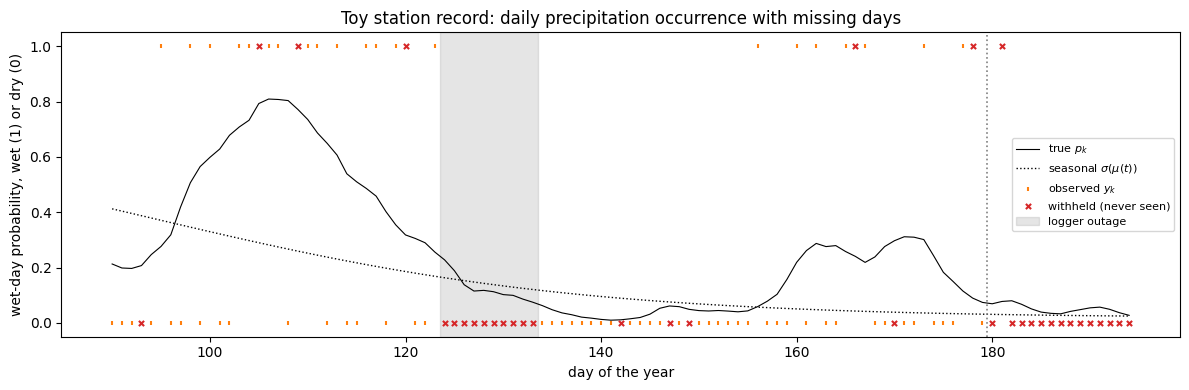

In [5]:
t_grid = np.asarray(days)  # → (T,)
seen = np.asarray(mask)  # → (T,) bool
missed = ~seen  # → (T,) bool

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_grid, prob_true, "k-", lw=0.8, label=r"true $p_k$")
ax.plot(
    t_grid, jax.nn.sigmoid(mu_true), "k:", lw=1.0, label=r"seasonal $\sigma(\mu(t))$"
)
ax.scatter(
    t_grid[seen],
    np.asarray(wet_full)[seen],
    c="C1",
    s=10,
    marker="|",
    label="observed $y_k$",
    zorder=5,
)
ax.scatter(
    t_grid[missed],
    np.asarray(wet_full)[missed],
    c="C3",
    s=14,
    marker="x",
    label="withheld (never seen)",
    zorder=5,
)
ax.axvspan(123.5, 133.5, color="grey", alpha=0.2, label="logger outage")
ax.axvline(FIRST_DAY + N_RECORD - 0.5, color="grey", ls=":", lw=1.2)
ax.set_xlabel("day of the year")
ax.set_ylabel("wet-day probability, wet (1) or dry (0)")
ax.set_title("Toy station record: daily precipitation occurrence with missing days")
ax.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()

## 2. Route A: the path integrated out

Both routes share the priors, which we put in one function. The offset gets $c \sim \mathcal{N}(-1, 1.5^2)$, so a station anywhere between much drier and much wetter than its climatology is plausible. The anomaly gets $\sigma_f^2 \sim \mathrm{LogNormal}(0, 1)$ and Example 1's prior for the lengthscale, $\ell \sim \mathrm{LogNormal}(\log 7, 1)$. The function returns the `MarkovGPPrior` with the seasonal mean as its `mean_fn`.

Route A then passes that prior, `BernoulliLikelihood()` and the record to `markov_laplace_factor`, which fits the sites with the strategy we give it and adds the approximate log evidence as a factor site named `"y"`. The masked days, stored as `NaN`, get a zero site and never reach the arithmetic. With `reject_unconverged=True` the factor is $-\infty$ whenever the fit stops at `max_iter` without meeting its tolerance, so NUTS rejects that $\boldsymbol{\theta}$ rather than move on an evidence and a gradient taken away from the fixed point.

In [6]:
def occurrence_prior(times):
    # Shapes: n days; D_θ = 3 parameters

    # today (numpyro): the three sample sites of θ
    # c ~ 𝒩(−1, 1.5²)
    offset = numpyro.sample("offset", dist.Normal(-1.0, 1.5))
    # σ_f² ~ LogNormal(0, 1)
    variance = numpyro.sample("variance", dist.LogNormal(0.0, 1.0))
    # ℓ ~ LogNormal(log 7, 1)
    lengthscale = numpyro.sample("lengthscale", dist.LogNormal(jnp.log(7.0), 1.0))

    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_f², ℓ) as a linear SDE
    sde = MaternSDE(variance, lengthscale, order=1)
    # today (pyrox_ssm)
    # μ + f ~ 𝒢𝒫(μ, k_Matérn-3/2) on the given days
    return MarkovGPPrior(sde, times, mean_fn=lambda t: climatology(t, offset))


# today (pyrox_gp)
# p(y_k ∣ f) = Bernoulli(σ(μ(t_k) + f(t_k)))
likelihood = BernoulliLikelihood()
# today (pyrox_ssm)
# damped Newton steps on the sites, s ← (1 − α) s + α 𝒯(s) with α = 0.5
laplace = LaplaceMarkovInference(damping=0.5, max_iter=50)


def collapsed_model(times, wet, mask, strategy=laplace):
    # Shapes: N record days; D_θ = 3 parameters

    # user
    prior = occurrence_prior(times)
    # today (pyrox_ssm)
    # log p(y ∣ θ) ≈ log p(y ∣ f̂) + log 𝒩(f̂; μ, K_tt) − ½ log det(I + Λ_site K_tt)
    markov_laplace_factor(
        "y",
        prior,
        likelihood,
        wet,
        strategy=strategy,
        mask=mask,
        reject_unconverged=True,
    )


def site_kind(site):
    """A short label for a trace site: factor, deterministic or its family."""
    if site["type"] != "sample":
        return site["type"]
    fn = site["fn"]
    if isinstance(fn, dist.Unit):
        return "factor"
    while isinstance(fn, (dist.ExpandedDistribution, dist.Independent)):
        fn = fn.base_dist
    if isinstance(fn, dist.MaskedDistribution):
        fn = fn.base_dist
    return type(fn).__name__


def print_trace(model, *args):
    """Every site of one seeded run of the model, and the values NUTS samples."""
    # today (numpyro)
    trace = handlers.trace(handlers.seed(model, rng_seed=0)).get_trace(*args)
    for name, site in trace.items():
        shape = tuple(jnp.shape(site["value"]))
        print(f"site {name!r:16} {site_kind(site):<14} value shape={shape}")
    n_latent = sum(
        int(np.prod(jnp.shape(site["value"])))
        for site in trace.values()
        if site["type"] == "sample"
        and not site["is_observed"]
        and not isinstance(site["fn"], dist.Unit)
    )
    print(f"unconstrained values for NUTS: {n_latent}")


print_trace(collapsed_model, record_days, record_wet, record_mask)

site 'offset'         Normal         value shape=()
site 'variance'       LogNormal      value shape=()
site 'lengthscale'    LogNormal      value shape=()
site 'y'              factor         value shape=(0,)
unconstrained values for NUTS: 3


So Route A's trace looks like Example 1's: three scalar sample sites and one factor, and no latent path.

We do not use the strategy's defaults (a full Newton step, `damping=1.0`, and `max_iter=20`). Without a line search a full Newton step can overshoot and oscillate when the prior variance is large, and then the fit stops at `max_iter` without converging. Under `reject_unconverged=True` that region of $\boldsymbol{\theta}$ becomes a wall of $-\infty$, which NUTS reports as divergences, and without it the factor there is an evidence and a gradient taken away from the fixed point. Below we fit both settings at four values of $\sigma_f^2$, with $c$ and $\ell$ at their true values, and print whether each fit converged and in how many iterations. Damping does not move the fixed point, so where both converge they give the same evidence, the damped one in more iterations.

In [7]:
# Shapes: N = 90 record days; 4 values of σ_f²

check_variance = jnp.array([1.0, 4.0, 8.0, 16.0])  # → (4,)


def fit_converged(variance, strategy):
    """Convergence and iterations at σ_f², with c and ℓ at the truth."""
    # today (pyrox_ssm)
    sde = MaternSDE(variance, truth["lengthscale"], order=1)
    # today (pyrox_ssm)
    prior = MarkovGPPrior(
        sde,
        record_days,
        mean_fn=lambda t: climatology(t, truth["offset"]),
    )
    # today (pyrox_ssm)
    cond = prior.condition_nongauss(
        likelihood, record_wet, strategy=strategy, mask=record_mask
    )
    return cond.converged, cond.n_iter


print(f"{'strategy':<36}" + "".join(f"{f'σ_f² = {v:g}':>14}" for v in check_variance))
for label, strategy in (
    ("defaults: damping 1.0, max_iter 20", LaplaceMarkovInference()),
    ("damping 0.5, max_iter 50", laplace),
):
    # today (jax)
    fits = jax.jit(jax.vmap(lambda v, s=strategy: fit_converged(v, s)))
    converged, n_iter = fits(check_variance)  # → (4,), (4,)
    row = f"{label:<36}"
    for ok, n in zip(np.asarray(converged), np.asarray(n_iter), strict=True):
        row += f"{('converged' if ok else 'stopped') + f' {n}':>14}"
    print(row)

strategy                                  σ_f² = 1      σ_f² = 4      σ_f² = 8     σ_f² = 16


defaults: damping 1.0, max_iter 20     converged 6   converged 8    stopped 20    stopped 20


damping 0.5, max_iter 50              converged 24  converged 25  converged 26  converged 27


With the defaults the fit converges in 6 and 8 iterations at $\sigma_f^2 = 1$ and 4, but at $\sigma_f^2 = 8$ and 16 it stops at `max_iter` without converging. The prior $\mathrm{LogNormal}(0, 1)$ does not rule these values out, so NUTS would meet them. With a damping of 0.5 the fit converges at all four, in 24 to 27 iterations. So every Route A evaluation below pays for about four times as many smoother passes as an undamped fit, and in exchange its evidence is defined wherever NUTS goes.

## 3. Route B: the path sampled

Route B builds the same prior on the whole grid of $T$ days, the record and the forecast, and draws the log odds with `markov_gp_innovations_sample("logit", prior)`, which registers the innovations as `"logit_eps"` and the path (mean included) as the deterministic site `"logit"`. The observation is a plain NumPyro Bernoulli site, masked with `.mask(mask)` and with the days as its event dimension. NumPyro's masked distribution still evaluates the log density on a masked day before it zeroes it, and a `NaN` there would turn the gradient into `NaN`, so Route B gets the record with 0 on the missed and forecast days, which are never read.

In [8]:
def latent_model(times, wet, mask):
    # Shapes: T grid days; D_x = 2; D_θ = 3 parameters

    # user
    prior = occurrence_prior(times)
    # today (pyrox_ssm)
    # μ(t_k) + f(t_k) = μ(t_k) + H x_k, x_k = F_k x_k−1 + L_η,k z_k
    logit = markov_gp_innovations_sample("logit", prior)  # → (T,)
    # today (numpyro)
    # y_k ~ Bernoulli(σ(μ(t_k) + f(t_k))) where o_k = 1
    numpyro.sample("y", dist.Bernoulli(logits=logit).mask(mask).to_event(1), obs=wet)


# 0 on the days with o_k = 0, which the masked site never reads
wet_filled = jnp.where(mask, wet_full, 0.0)  # → (T,)
print_trace(latent_model, days, wet_filled, mask)

site 'offset'         Normal         value shape=()
site 'variance'       LogNormal      value shape=()
site 'lengthscale'    LogNormal      value shape=()
site 'logit_eps'      Normal         value shape=(105, 2)
site 'logit'          deterministic  value shape=(105,)
site 'y'              BernoulliLogits value shape=(105,)
unconstrained values for NUTS: 213


Route B's trace holds the same three sample sites, the $T \times D_x$ innovations, the deterministic path and the masked Bernoulli site, so NUTS moves $3 + T D_x = 213$ values.

## 4. NUTS on both routes

Route A has three values to sample, so, as in Example 1, we give it a dense mass matrix (`dense_mass=True`). Its log density is the expensive one (a damped Laplace fit and its implicit gradient), so we keep its run short, with 50 warm-up steps and 50 draws per chain. We also cap the tree depth at 4 (at most 15 leapfrog steps per draw), which is plenty for three values once the mass matrix is adapted. Route B has 213 values, so, as in Example 3b, only the three hyperparameters share a dense block of the mass matrix, and the innovations stay on the diagonal. Its log density is one scan, so it gets 150 warm-up steps and 150 draws per chain. Both routes run their chains one after the other with `chain_method="sequential"`. We avoid `"parallel"`, under which `markov_gp_innovations_sample` with its default Cholesky square root fails (issue #420). Both start at the prior medians, and the wall-clock times include JIT compilation.

In [9]:
# Shapes: D_θ = 3; T D_x = 210 innovations; 2 chains per route

hyper_names = list(truth)


def run_nuts(
    model, args, *, warmup, samples, chain_method, dense_mass, max_tree_depth, seed
):
    """Two NUTS chains; the samples, the run time and the sampler statistics."""
    # today (numpyro)
    kernel = NUTS(
        model,
        init_strategy=init_to_median,
        dense_mass=dense_mass,
        max_tree_depth=max_tree_depth,
    )
    # today (numpyro)
    mcmc = MCMC(
        kernel,
        num_warmup=warmup,
        num_samples=samples,
        num_chains=2,
        chain_method=chain_method,
        progress_bar=False,
    )
    t0 = time.perf_counter()
    # today (numpyro)
    mcmc.run(jr.PRNGKey(seed), *args, extra_fields=("num_steps",))
    jax.block_until_ready(mcmc.get_samples())
    seconds = time.perf_counter() - t0
    by_chain = mcmc.get_samples(group_by_chain=True)  # → {name: (2, samples, …)}
    stats = summary({k: by_chain[k] for k in hyper_names})
    fields = mcmc.get_extra_fields()
    return {
        "samples": mcmc.get_samples(),
        "by_chain": by_chain,
        "seconds": seconds,
        "steps_per_draw": float(fields["num_steps"].mean()),
        "steps": int(fields["num_steps"].sum()),
        "divergences": int(fields["diverging"].sum()),
        "diverging": np.asarray(fields["diverging"]),
        "min_n_eff": min(float(stats[k]["n_eff"]) for k in hyper_names),
        "max_r_hat": max(float(stats[k]["r_hat"]) for k in hyper_names),
    }


runs = {}
# Route A: three values, a dense mass matrix
runs["A, Laplace"] = run_nuts(
    collapsed_model,
    (record_days, record_wet, record_mask),
    warmup=50,
    samples=50,
    chain_method="sequential",
    dense_mass=True,
    max_tree_depth=4,
    seed=1,
)
# Route B: a dense block for θ, the innovations on the diagonal
runs["B, latent"] = run_nuts(
    latent_model,
    (days, wet_filled, mask),
    warmup=150,
    samples=150,
    chain_method="sequential",
    dense_mass=[tuple(hyper_names)],
    max_tree_depth=10,
    seed=2,
)
for label, run in runs.items():
    print(
        f"{label:<12} {run['seconds']:6.1f} s, {run['steps_per_draw']:5.1f} "
        f"leapfrog steps per draw, {run['divergences']} divergences, "
        f"smallest n_eff {run['min_n_eff']:.0f}, largest r_hat {run['max_r_hat']:.3f}"
    )
# where Route A's divergent transitions are, in σ_f² and ℓ
run_a = runs["A, Laplace"]
for k in ("variance", "lengthscale") if run_a["divergences"] else ():
    v = np.asarray(run_a["samples"][k])
    print(
        f"Route A {k}: median {np.median(v):.2f} over all draws, "
        f"{np.median(v[run_a['diverging']]):.2f} over the divergent ones"
    )

A, Laplace    112.8 s,   6.8 leapfrog steps per draw, 1 divergences, smallest n_eff 50, largest r_hat 1.020
B, latent      31.2 s,  24.6 leapfrog steps per draw, 0 divergences, smallest n_eff 193, largest r_hat 1.004
Route A variance: median 1.10 over all draws, 0.46 over the divergent ones
Route A lengthscale: median 12.23 over all draws, 15.54 over the divergent ones


Both routes mix well enough for the comparison. Route A has one divergence in its 100 draws (at $\sigma_f^2 = 0.46$ and $\ell = 15.5$ days, far from the large variances where the undamped fit failed), a largest $\hat{R}$ of 1.020 and a smallest effective sample size of 50 over the three hyperparameters. Route B has no divergences, a largest $\hat{R}$ of 1.004 and a smallest effective sample size of 193 from 300 draws. Route A needs 6.8 leapfrog steps per draw against Route B's 24.6, as it samples three values instead of 213. However, its 100 draws took 112.8 s, against 31.2 s for Route B's 300.

## 5. The hyperparameters against the truth

For each hyperparameter we print the posterior mean, standard deviation and 90 % interval of each route, next to the value we simulated the record with.

In [10]:
labels = list(runs)
header = f"{'parameter':<12}{'truth':>8}"
for label in labels:
    header += f"  {label + ' mean ± sd':>22}  {'90% interval':>22}"
print(header)
for k in hyper_names:
    row = f"{k:<12}{truth[k]:>8.2f}"
    for label in labels:
        v = np.asarray(runs[label]["samples"][k])
        lo, hi = np.percentile(v, [5, 95])
        inside = "in" if lo <= truth[k] <= hi else "out"
        row += (
            f"  {v.mean():>13.3f} ± {v.std():<6.3f}  "
            f"[{lo:>7.3f}, {hi:>7.3f}] {inside:>3}"
        )
    print(row)

parameter      truth    A, Laplace mean ± sd            90% interval     B, latent mean ± sd            90% interval
offset         -1.50         -0.780 ± 0.581   [ -2.014,   0.096]  in         -0.719 ± 0.654   [ -1.772,   0.137]  in
variance        1.00          1.353 ± 0.991   [  0.275,   3.364]  in          1.684 ± 1.418   [  0.307,   4.570]  in
lengthscale     8.00         12.524 ± 6.372   [  4.339,  25.082]  in         11.800 ± 7.803   [  3.253,  26.898]  in


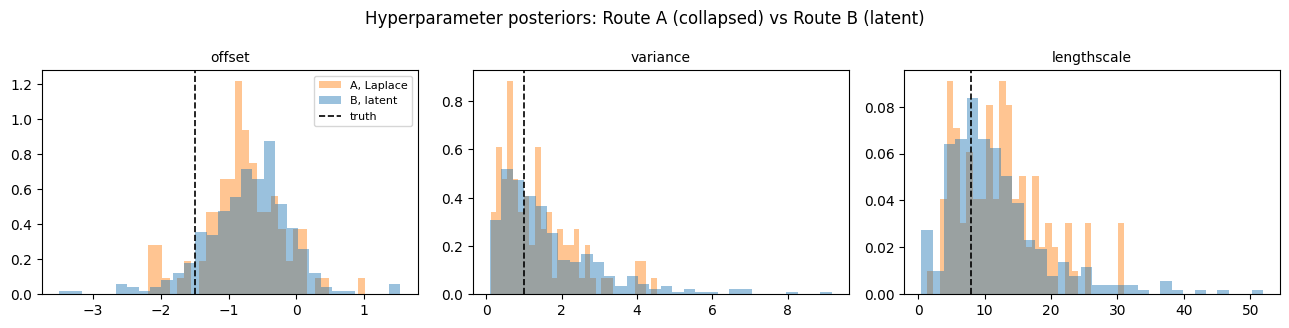

In [11]:
colors = {"A, Laplace": "C1", "A, EP": "C2", "B, latent": "C0"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, k in zip(axes, hyper_names, strict=True):
    for label in labels:
        ax.hist(
            np.asarray(runs[label]["samples"][k]),
            bins=30,
            density=True,
            alpha=0.45,
            color=colors[label],
            label=label,
        )
    ax.axvline(truth[k], color="k", ls="--", lw=1.2, label="truth")
    ax.set_title(k, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Hyperparameter posteriors: Route A (collapsed) vs Route B (latent)")
plt.tight_layout()
plt.show()

Both routes have all three true values inside their 90 % intervals, and they agree on the offset ($c$ = −0.78 ± 0.58 for Route A, −0.72 ± 0.65 for Route B) and on the lengthscale (12.5 ± 6.4 against 11.8 ± 7.8 days). Both put the offset above the true −1.5 and the lengthscale above the true 8 days. Since the two routes agree, this belongs to the record (70 observed wet or dry days say little about either), not to the method. They differ in the variance. Route A's posterior of $\sigma_f^2$ has a mean of 1.35 and a 90 % interval up to 3.36, Route B's a mean of 1.68 and an interval up to 4.57. So the Laplace evidence trims the upper tail of $\sigma_f^2$. With 100 draws the histograms of Route A are rough, but the difference is in the place where we would expect the Gaussian approximation to be worst, as a larger $\sigma_f^2$ puts more of the log odds where the logistic function saturates.

## 6. The wet-day probability through the gaps and the forecast

Route B's draws $e \in \mathcal{E}$ carry the log odds on every day of the grid, so its wet-day probability is $p_k^{(e)} = \sigma(\mu^{(e)}(t_k) + f^{(e)}(t_k))$, with no extra step, as in Example 3b. Route A's draws carry only $\boldsymbol{\theta}^{(e)}$. For each of $N_{\mathcal{E}} = 100$ of them we refit the Laplace sites with `condition_nongauss` and call `predict` at all $T$ days of the grid, which gives the Gaussian $q(\mu(t_k) + f(t_k) \mid \mathbf{y}, \boldsymbol{\theta}^{(e)}) = \mathcal{N}(\mu_k^{(e)}, (\sigma_k^{(e)})^2)$, also on the withheld days and the forecast, where the smoother runs its predict step only. The wet-day probability is a nonlinear function of the log odds, so we draw $N_\text{MC} = 20$ log odds from each Gaussian, push them through $\sigma(\cdot)$ and pool the $N_{\mathcal{E}} N_\text{MC}$ values. For both routes we then summarise $p_k$ by its posterior mean, which is also the predictive probability of a wet day, $\mathbb{P}(y_k = 1 \mid \mathbf{y})$, and by the 2.5 % and 97.5 % quantiles, the 95 % band.

In [12]:
# Shapes: T = 105 grid days; N = 90 record days; N_E = 100 draws; N_MC = 20

N_DRAWS = 100
N_MC = 20


def evenly_spaced(samples, n_draws=N_DRAWS):
    """n_draws draws evenly spaced through the chains."""
    num_samples = samples["variance"].shape[0]
    idx = jnp.linspace(0, num_samples - 1, n_draws).astype(int)  # → (N_E,)
    return {k: samples[k][idx] for k in hyper_names}


def conditioned_one(theta, strategy):
    """Fit the sites for one θ⁽ᵉ⁾ and predict the log odds at every grid day."""
    # today (pyrox_ssm)
    sde = MaternSDE(theta["variance"], theta["lengthscale"], order=1)
    # today (pyrox_ssm)
    prior = MarkovGPPrior(
        sde,
        record_days,
        mean_fn=lambda t: climatology(t, theta["offset"]),
    )
    # today (pyrox_ssm)
    # q(f ∣ y; θ⁽ᵉ⁾) from the sites fitted by the strategy
    cond = prior.condition_nongauss(
        likelihood, record_wet, strategy=strategy, mask=record_mask
    )
    # today (pyrox_ssm)
    # μ_k⁽ᵉ⁾, (σ_k⁽ᵉ⁾)² of μ(t_k) + f(t_k) at all T days
    mean, var = cond.predict(days)  # (T,) → (T,), (T,)
    return mean, var, cond.converged, cond.n_iter


def conditioned_draws(theta_draws, strategy):
    """conditioned_one for every draw, vectorised and jitted."""
    # today (jax)
    one = jax.vmap(lambda theta: conditioned_one(theta, strategy))
    # today (jax)
    return jax.jit(one)(theta_draws)  # → (N_E, T), (N_E, T), (N_E,), (N_E,)


def prob_summary(prob_draws):
    """Mean and 95 % band of p_k over the pooled draw axis."""
    # p̄_k = (1/N_draws) ∑ p_k⁽ᵉ⁾, also ℙ(y_k = 1 ∣ y)
    mean = einx.mean("draw k -> k", prob_draws)  # → (T,)
    # the 2.5 % and 97.5 % quantiles over the draws
    lo, hi = np.percentile(np.asarray(prob_draws), [2.5, 97.5], axis=0)
    return {"mean": np.asarray(mean), "lo": lo, "hi": hi}


def collapsed_probabilities(theta_draws, strategy, key):
    """Pooled draws of p_k from the Gaussian q of every θ⁽ᵉ⁾."""
    means, variances, converged, n_iter = conditioned_draws(theta_draws, strategy)
    # ε ~ 𝒩(0, 1), N_MC per draw and day
    noise = jr.normal(key, (N_MC, *means.shape))  # → (N_MC, N_E, T)
    # μ_k⁽ᵉ⁾ + σ_k⁽ᵉ⁾ ε
    logit_draws = einx.add(  # → (N_MC, N_E, T)
        "e k, m e k -> m e k",
        means,
        einx.multiply("e k, m e k -> m e k", jnp.sqrt(variances), noise),
    )
    # p_k = σ(μ(t_k) + f(t_k)), pooled over the draws and the N_MC values
    prob_draws = einx.id("m e k -> (m e) k", jax.nn.sigmoid(logit_draws))
    return prob_draws, means, variances, converged, n_iter


t0 = time.perf_counter()
theta_a = evenly_spaced(runs["A, Laplace"]["samples"])
prob_draws_a, means_a, vars_a, converged_a, n_iter_a = collapsed_probabilities(
    theta_a, laplace, jr.PRNGKey(5)
)
jax.block_until_ready(prob_draws_a)
pred_seconds = time.perf_counter() - t0
summaries = {"A, Laplace": prob_summary(prob_draws_a)}
# p_k⁽ᵉ⁾ = σ(μ⁽ᵉ⁾(t_k) + f⁽ᵉ⁾(t_k)) for every Route B draw
prob_draws_b = jax.nn.sigmoid(runs["B, latent"]["samples"]["logit"])  # → (N_B, T)
summaries["B, latent"] = prob_summary(prob_draws_b)
print(
    f"Route A prediction for {N_DRAWS} draws at {N_DAYS} days: {pred_seconds:.1f} s "
    f"(with JIT); Laplace fits converged for {int(converged_a.sum())} of {N_DRAWS} "
    f"draws, in {float(n_iter_a.mean()):.1f} iterations on average "
    f"(at most {int(n_iter_a.max())})"
)

Route A prediction for 100 draws at 105 days: 5.9 s (with JIT); Laplace fits converged for 100 of 100 draws, in 24.7 iterations on average (at most 27)


The top panel shows the wet-day probability: Route B's 95 % band and mean in blue, Route A's band (dashed) and mean in orange, the true $p_k$ as a thin black line, the observed days as ticks at 0 and 1 and the withheld days as red crosses. The outage is shaded and the forecast starts at the dotted line. A probability near zero squeezes every band together, so the bottom panel shows the same quantiles on the log-odds scale, where the dry end of the record is visible.

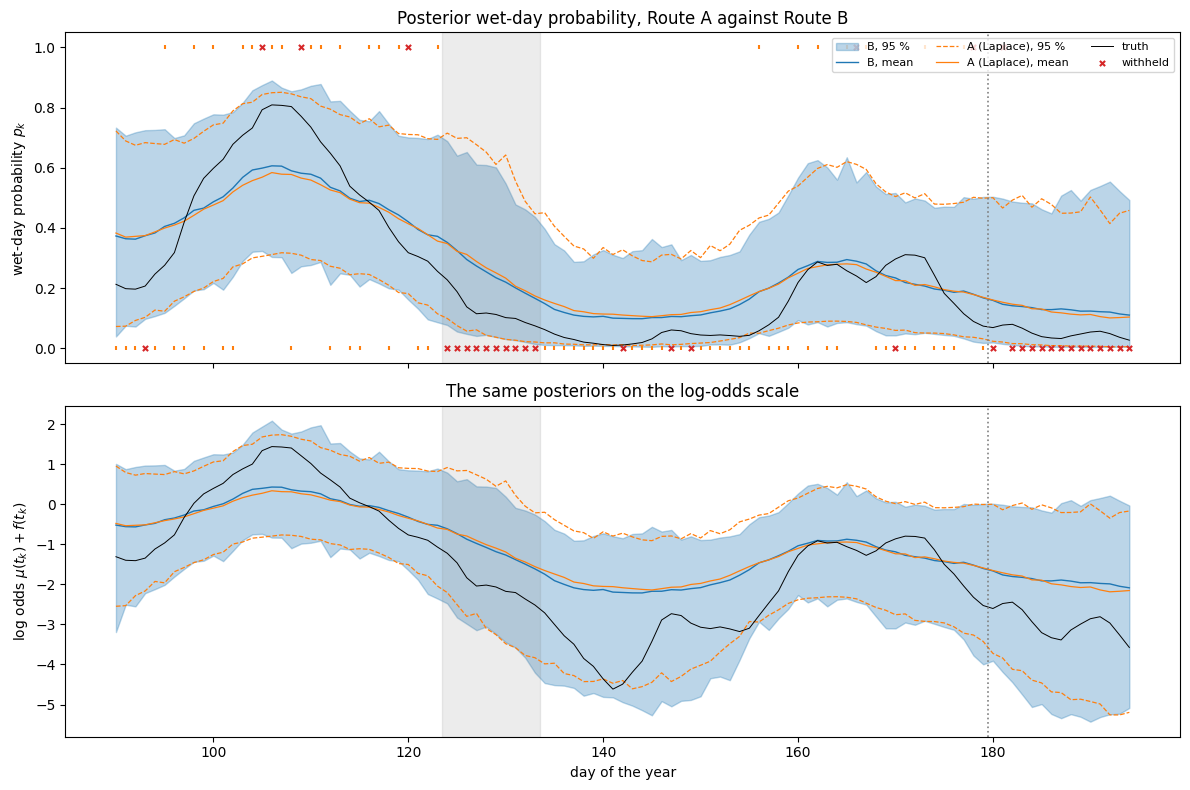

In [13]:
def identity(p):
    return p


def to_log_odds(p):
    """log(p / (1 − p)); a quantile of p maps to the same quantile of the log odds."""
    return np.log(p) - np.log1p(-p)


fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, tx in zip(axes, (identity, to_log_odds), strict=True):
    sb, sa = summaries["B, latent"], summaries["A, Laplace"]
    ax.fill_between(
        t_grid, tx(sb["lo"]), tx(sb["hi"]), color="C0", alpha=0.3, label="B, 95 %"
    )
    ax.plot(t_grid, tx(sb["mean"]), "C0", lw=1.0, label="B, mean")
    ax.plot(t_grid, tx(sa["lo"]), "C1--", lw=0.9, label="A (Laplace), 95 %")
    ax.plot(t_grid, tx(sa["hi"]), "C1--", lw=0.9)
    ax.plot(t_grid, tx(sa["mean"]), "C1", lw=0.9, label="A (Laplace), mean")
    ax.plot(t_grid, tx(np.asarray(prob_true)), "k-", lw=0.7, label="truth")
    ax.axvspan(123.5, 133.5, color="grey", alpha=0.15)
    ax.axvline(FIRST_DAY + N_RECORD - 0.5, color="grey", ls=":", lw=1.2)
axes[0].scatter(
    t_grid[seen], np.asarray(wet_full)[seen], c="C1", s=10, marker="|", zorder=5
)
axes[0].scatter(
    t_grid[missed],
    np.asarray(wet_full)[missed],
    c="C3",
    s=14,
    marker="x",
    zorder=5,
    label="withheld",
)
axes[0].set_ylabel("wet-day probability $p_k$")
axes[0].set_title("Posterior wet-day probability, Route A against Route B")
axes[0].legend(loc="upper right", fontsize=8, ncol=3)
axes[1].set_ylabel(r"log odds $\mu(t_k) + f(t_k)$")
axes[1].set_xlabel("day of the year")
axes[1].set_title("The same posteriors on the log-odds scale")
plt.tight_layout()
plt.show()

The two routes give almost the same picture. Both posterior means smooth the wet and dry days into a wet spell in April, a dry May and a smaller wet spell in June, and both bands hold the true $p_k$ on nearly every day. Through the outage and in the forecast the bands widen, and in the forecast they relax towards the seasonal mean and the stationary spread of the anomaly, as the Gaussian bands did in Example 1. The visible difference is in May. On the log-odds scale Route A's band sits a little above Route B's through the run of dry days after the outage, and section 7 shows where that comes from.

Because the record is simulated, we know $p_k$ on every day and whether each withheld day was wet. A 95 % predictive interval for a single 0 or 1 is not a useful check, since it holds both outcomes unless $\mathbb{P}(y_k = 1 \mid \mathbf{y})$ is below 2.5 % or above 97.5 %. So we score each route in two ways. The first is the fraction of days on which the true $p_k$ is inside the 95 % band (the coverage of the latent probability). The second, on the withheld days and the forecast, is the mean log predictive density, $\frac{1}{N_\text{sel}} \sum_k \log \mathbb{P}(y_k \mid \mathbf{y})$ over the $N_\text{sel}$ selected days (higher is better), and the Brier score, $\frac{1}{N_\text{sel}} \sum_k (\mathbb{P}(y_k = 1 \mid \mathbf{y}) - y_k)^2$ (lower is better). The scores of the true $p_k$ are the best that any model of these days can do on average.

In [14]:
# Shapes: T = 105 grid days

kinds = {
    "observed days": np.asarray(mask),
    "isolated dropouts": np.asarray(in_record & dropout & ~outage),
    "outage (5-14 May)": np.asarray(outage),
    "forecast": np.asarray(~in_record),
}
wet_np = np.asarray(wet_full)  # → (T,)
prob_np = np.asarray(prob_true)  # → (T,)


def scores(prob, sel):
    """Mean log predictive density and Brier score of ℙ(y_k = 1) on sel."""
    # log ℙ(y_k ∣ y) = y_k log p̄_k + (1 − y_k) log(1 − p̄_k)
    log_pred = wet_np * np.log(prob) + (1.0 - wet_np) * np.log1p(-prob)  # → (T,)
    # (p̄_k − y_k)²
    brier = (prob - wet_np) ** 2  # → (T,)
    return float(np.mean(log_pred[sel])), float(np.mean(brier[sel]))


print(
    f"{'days':<22}{'n':>4}{'p in 95% band':>16}{'':>3}"
    f"{'log predictive density':>26}{'':>3}{'Brier score':>22}"
)
print(
    f"{'':<26}{'A':>8}{'B':>8}{'':>3}{'A':>8}{'B':>8}{'truth':>8}"
    f"{'':>5}{'A':>7}{'B':>7}{'truth':>8}"
)
for label, sel in kinds.items():
    row = f"{label:<22}{int(sel.sum()):>4}"
    for name in ("A, Laplace", "B, latent"):
        s = summaries[name]
        inside = (prob_np >= s["lo"]) & (prob_np <= s["hi"])
        row += f"{100 * np.mean(inside[sel]):>7.1f}%"
    if label == "observed days":
        print(row)
        continue
    lpd = [scores(summaries[n]["mean"], sel)[0] for n in ("A, Laplace", "B, latent")]
    brier = [scores(summaries[n]["mean"], sel)[1] for n in ("A, Laplace", "B, latent")]
    lpd_true, brier_true = scores(prob_np, sel)
    row += f"{'':>3}{lpd[0]:>8.3f}{lpd[1]:>8.3f}{lpd_true:>8.3f}"
    row += f"{'':>5}{brier[0]:>7.3f}{brier[1]:>7.3f}{brier_true:>8.3f}"
    print(row)

days                     n   p in 95% band       log predictive density              Brier score
                                 A       B          A       B   truth           A      B   truth
observed days           70   95.7%  100.0%
isolated dropouts       10   90.0%  100.0%     -0.610  -0.594  -0.619       0.214  0.208   0.210
outage (5-14 May)       10  100.0%  100.0%     -0.303  -0.291  -0.136       0.070  0.066   0.018
forecast                15  100.0%  100.0%     -0.246  -0.257  -0.218       0.062  0.064   0.059


On the 70 observed days the true $p_k$ is inside Route B's 95 % band on every day and inside Route A's on 95.7 % of them. On the outage and the forecast both bands hold it on every day, and on the 10 isolated dropouts Route B's does on all of them and Route A's on 9 (90.0 %). The scores of the predictive probabilities differ by at most 0.016 in log predictive density (−0.303 for Route A against −0.291 for Route B on the outage, −0.246 against −0.257 on the forecast), and the Brier scores by at most 0.006. The true $p_k$ scores much better on the outage (−0.136), where neither model can know the path. On the isolated dropouts it scores a little worse than both (−0.619), which with 10 days is noise.

## 7. Where the Laplace approximation is biased

Route A approximates in two places. Its hyperparameter posterior comes from the approximate evidence, and for each $\boldsymbol{\theta}$ its latent posterior is a Gaussian $q(\mathbf{f} \mid \mathbf{y}, \boldsymbol{\theta})$ centred at the mode. To separate the two, we condition on Route B's own hyperparameter draws: for $N_{\mathcal{E}} = 100$ of them we fit the Laplace sites and, for comparison, the EP sites of `ExpectationPropagationMarkov`, and compare the resulting latent posteriors with Route B's, which is exact for the same draws. Any difference is then the error of the Gaussian approximation alone. We compare the posterior mean and standard deviation of the log odds $\mu(t_k) + f(t_k)$, mixed over the draws as in Example 1, in each month of the record: the wet start in April, May with the outage and a long dry run, and the dry June.

In [15]:
# Shapes: T = 105 grid days; N_E = 100 draws

theta_b = evenly_spaced(runs["B, latent"]["samples"])
logit_b = np.asarray(runs["B, latent"]["samples"]["logit"])  # → (N_B, T)
# the mean and sd of the log odds over Route B's draws
latent = {"B, latent": (logit_b.mean(axis=0), logit_b.std(axis=0))}


def mixture(means, variances):
    """Mean and sd of the equal-weight Gaussian mixture over the draw axis."""
    # μ̄_k = (1/N_E) ∑ₑ μ_k⁽ᵉ⁾
    mean = einx.mean("member k -> k", means)
    # (1/N_E) ∑ₑ (μ_k⁽ᵉ⁾ − μ̄_k)²
    spread = einx.var("member k -> k", means)
    # (1/N_E) ∑ₑ (σ_k⁽ᵉ⁾)²
    variance_mean = einx.mean("member k -> k", variances)
    # 𝕍 ≈ (1/N_E) ∑ₑ (σ_k⁽ᵉ⁾)² + spread
    return np.asarray(mean), np.asarray(jnp.sqrt(variance_mean + spread))


t0 = time.perf_counter()
ep = ExpectationPropagationMarkov()
fit_stats = {}
for label, strategy in (("Laplace | θ_B", laplace), ("EP | θ_B", ep)):
    means, variances, converged, n_iter = conditioned_draws(theta_b, strategy)
    latent[label] = mixture(means, variances)
    fit_stats[label] = (int(converged.sum()), float(n_iter.mean()))
latent["A, Laplace"] = mixture(means_a, vars_a)
cond_seconds = time.perf_counter() - t0
print(f"Laplace and EP fits for {N_DRAWS} Route B draws: {cond_seconds:.1f} s")
for label, (n_conv, iters) in fit_stats.items():
    print(f"  {label:<14} converged {n_conv} of {N_DRAWS}, {iters:.1f} iterations")
print()
print(f"{'latent posterior':<20}{'mean − B mean':>27}{'':>4}{'sd / B sd':>27}")
print(
    f"{'':<20}"
    + "".join(f"{m:>9}" for m in months)
    + f"{'':>4}"
    + "".join(f"{m:>9}" for m in months)
)
mean_b, sd_b = latent["B, latent"]
for label in ("Laplace | θ_B", "EP | θ_B", "A, Laplace"):
    mean_l, sd_l = latent[label]
    row = f"{label:<20}"
    for sel in months.values():
        row += f"{float(np.mean((mean_l - mean_b)[np.asarray(sel)])):>9.3f}"
    row += f"{'':>4}"
    for sel in months.values():
        row += f"{float(np.mean((sd_l / sd_b)[np.asarray(sel)])):>9.2f}"
    print(row)

Laplace and EP fits for 100 Route B draws: 6.5 s
  Laplace | θ_B  converged 100 of 100, 24.9 iterations
  EP | θ_B       converged 100 of 100, 21.5 iterations

latent posterior                  mean − B mean                      sd / B sd
                        April      May     June        April      May     June
Laplace | θ_B          -0.002    0.152    0.063         0.95     0.96     0.98
EP | θ_B               -0.010    0.036   -0.026         0.98     1.01     0.99
A, Laplace             -0.047    0.141    0.015         0.89     0.87     0.93


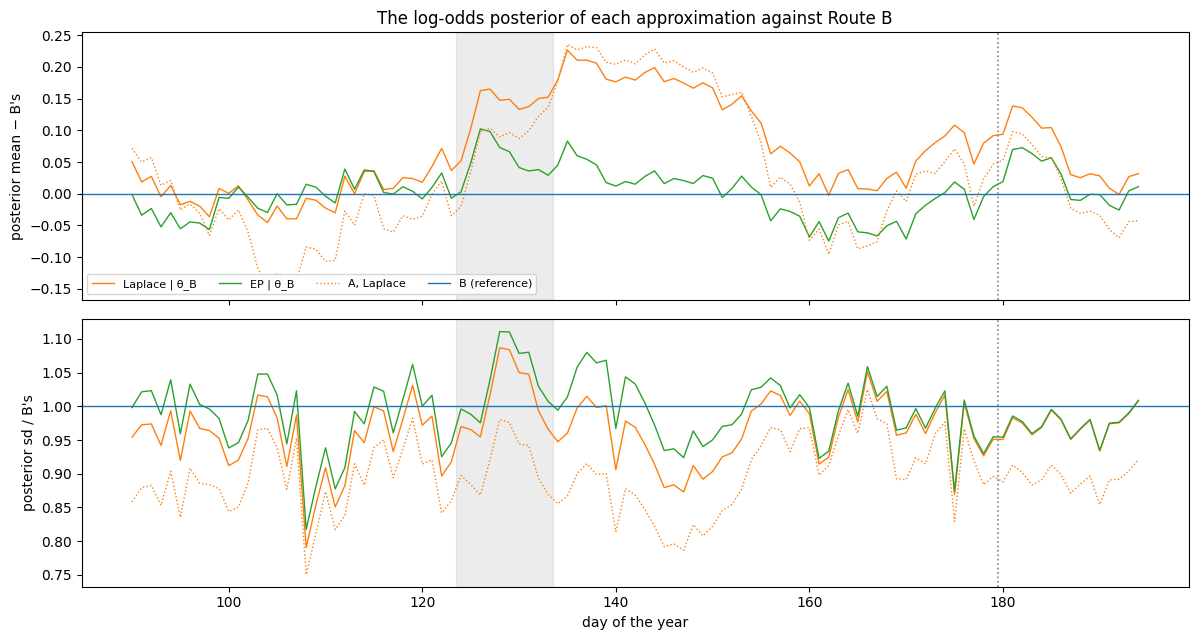

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
styles = {
    "Laplace | θ_B": ("C1", "-"),
    "EP | θ_B": ("C2", "-"),
    "A, Laplace": ("C1", ":"),
}
for label, (color, ls) in styles.items():
    mean_l, sd_l = latent[label]
    axes[0].plot(t_grid, mean_l - mean_b, color=color, ls=ls, lw=1.0, label=label)
    axes[1].plot(t_grid, sd_l / sd_b, color=color, ls=ls, lw=1.0, label=label)
axes[0].axhline(0.0, color="C0", lw=1.0, label="B (reference)")
axes[1].axhline(1.0, color="C0", lw=1.0, label="B (reference)")
for ax in axes:
    ax.axvspan(123.5, 133.5, color="grey", alpha=0.15)
    ax.axvline(FIRST_DAY + N_RECORD - 0.5, color="grey", ls=":", lw=1.2)
axes[0].set_ylabel("posterior mean − B's")
axes[1].set_ylabel("posterior sd / B's")
axes[1].set_xlabel("day of the year")
axes[0].set_title("The log-odds posterior of each approximation against Route B")
axes[0].legend(loc="lower left", fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

With Route B's own hyperparameters, the Laplace posterior of the log odds matches Route B's in April (a mean difference of −0.002 and a standard deviation ratio of 0.95) and in June (0.063 and 0.98). In May it does not. There the record holds 1 wet day in 17 observed days, and the Laplace mean sits on average 0.152 above Route B's, most of all in the run of dry days after the outage (top panel). EP at the same hyperparameters stays within 0.036 of Route B in May and within 0.026 in the other months. This is the sparse binary case. A run of dry days skews the posterior of the log odds, with a long tail towards very negative values (a dry day says little about how dry the day was). A Gaussian centred at the mode then sits above the mean of such a distribution. EP matches the mean and variance of the tilted distribution at each site, rather than the curvature at the mode, so it follows the skew.

Route A's own posterior (dotted) also carries its trimmed $\sigma_f^2$. Its bands are narrower than Route B's in every month (standard deviation ratios of 0.89, 0.87 and 0.93), whereas the Laplace bands at Route B's hyperparameters are not (0.95 to 0.98). So in this example the Laplace approximation costs Route A a shift of about 0.14 in the log odds where the data are sparse, and somewhat narrower bands through the hyperparameters. Both are small next to the width of the bands, which is why the coverage and the scores of section 6 barely differ.

## 8. Cost

We compare the two routes in three ways. First, the time of one jitted log density and its gradient, at the prior medians and with Route B's innovations at zero. Second, the NUTS wall-clock time and the leapfrog steps per draw from section 4. Third, the smallest effective sample size over the three hyperparameters per second of NUTS, which is the number that decides which route is cheaper for $\boldsymbol{\theta}$.

In [17]:
def time_grad(model, args, values, repeats=3):
    """One jitted log joint density and its gradient, in ms."""

    def log_joint(v):
        # today (numpyro)
        # log p(θ, ·, y) at the given unconstrained sample values
        log_p, _ = log_density(model, args, {}, v)
        return log_p

    # today (jax)
    loss_and_grad = jax.jit(jax.value_and_grad(log_joint))
    jax.block_until_ready(loss_and_grad(values))
    t0 = time.perf_counter()
    for _ in range(repeats):
        jax.block_until_ready(loss_and_grad(values))
    return 1e3 * (time.perf_counter() - t0) / repeats


theta_median = {
    "offset": jnp.asarray(-1.0),
    "variance": jnp.asarray(1.0),
    "lengthscale": jnp.asarray(7.0),
}
grad_ms = {
    "A, Laplace": time_grad(
        collapsed_model, (record_days, record_wet, record_mask), theta_median
    ),
    "B, latent": time_grad(
        latent_model,
        (days, wet_filled, mask),
        {**theta_median, "logit_eps": jnp.zeros((N_DAYS, 2))},
    ),
}
print(
    f"{'route':<12}{'grad, ms':>10}{'NUTS, s':>10}{'steps/draw':>12}"
    f"{'draws':>7}{'min n_eff':>11}{'n_eff / s':>11}"
)
for label, run in runs.items():
    n_draws = run["samples"]["variance"].shape[0]
    row = f"{label:<12}{grad_ms.get(label, float('nan')):>10.2f}"
    row += f"{run['seconds']:>10.1f}{run['steps_per_draw']:>12.1f}{n_draws:>7}"
    row += f"{run['min_n_eff']:>11.0f}{run['min_n_eff'] / run['seconds']:>11.2f}"
    print(row)
print()
print(f"Route A prediction: {pred_seconds:.1f} s ({N_DRAWS} draws x {N_DAYS} days)")
print(f"Laplace and EP at Route B's draws: {cond_seconds:.1f} s")

route         grad, ms   NUTS, s  steps/draw  draws  min n_eff  n_eff / s
A, Laplace       32.33     112.8         6.8    100         50       0.44
B, latent         0.62      31.2        24.6    300        193       6.21

Route A prediction: 5.9 s (100 draws x 105 days)
Laplace and EP at Route B's draws: 6.5 s


One log density and its gradient cost 32.3 ms for Route A and 0.62 ms for Route B, about fifty times more. Route A runs the damped fixed-point iteration to convergence (about 25 smoother passes here, from section 6) and then solves the implicit adjoint with GMRES, each step of which is another pass. Route B runs one scan over the 105 days and its reverse pass. Route A makes up some of this in the number of steps, 6.8 leapfrog steps per draw against 24.6, because it samples three values rather than 213. Per draw that is still about fourteen times the work of Route B, and per effective sample of the hyperparameters Route B is ahead by a similar factor, 6.21 against 0.44 per second (both including JIT compilation). So on a CPU and at this record length the sampled path is the cheaper route to the hyperparameters. Route A gives the smaller posterior: three values, few steps per draw, and no mass matrix to adapt over the path.

## Summary

- A Bernoulli model on a Markov GP is a plain NumPyro function either way. Route A calls `markov_laplace_factor(..., strategy=LaplaceMarkovInference(damping=0.5, max_iter=50), mask=mask, reject_unconverged=True)`, so its trace holds three sample sites and one factor. Route B calls `markov_gp_innovations_sample` and adds a masked Bernoulli site, so NUTS moves 213 values.
- The strategy's defaults (a full Newton step, 20 iterations) stop without converging at $\sigma_f^2 = 8$ and 16 on this record. A damping of 0.5 converged at all four values we checked, in 24 to 27 iterations.
- The two routes agree on the offset and the lengthscale, and both hold all three true values in their 90 % intervals. The Laplace evidence trims the upper tail of $\sigma_f^2$ (a 90 % interval up to 3.36, against 4.57 for Route B).
- Route A's prediction, `condition_nongauss(...).predict(...)` averaged over 100 NUTS draws, follows Route B's through the outage and the forecast. Both bands hold the true $p_k$ on every outage and forecast day, and the log predictive densities differ by at most 0.016.
- The Laplace latent posterior is close to exact where the data are informative (April, June) and 0.152 too high in the log odds in May, the sparse month with 1 wet day in 17, where EP stays within 0.036.
- Route A costs 32.3 ms per gradient against 0.62 ms and needs 6.8 leapfrog steps per draw against 24.6, so here Route B gives 6.21 effective samples per second against 0.44.

For the four site-based strategies at fixed hyperparameters see [Non-Gaussian Markov GP inference](markov_gp_nongauss.ipynb), for whitened paths in a spatial model [Example 3b](ssm_spatial_hierarchical.ipynb), and for the Gaussian case with the Kalman filter [Example 1](ssm_one_site.ipynb).